In [1]:
# Load labels
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Works when the notebook is inside data_labeling/eda.
root = Path.cwd().parents[1]
path = root / "data_labeling/data_labels/noaa/labels_noaa_2010_2026_binary.csv"

labels = pd.read_csv(path)
labels["year"] = labels["label"].str[:4].astype(int)

print("Total images:", len(labels))
labels.head()

Total images: 128117


,label,goes_class,year
0,2010/12/06/HMI.m2010.12.06_07.00.00.jpg,0,2010
1,2010/12/06/HMI.m2010.12.06_08.00.00.jpg,0,2010
2,2010/12/06/HMI.m2010.12.06_09.00.00.jpg,0,2010
3,2010/12/06/HMI.m2010.12.06_10.00.00.jpg,0,2010
4,2010/12/06/HMI.m2010.12.06_11.00.00.jpg,0,2010


In [2]:
print("Missing values:\n", labels.isna().sum())
print("\nDuplicate paths:", labels["label"].duplicated().sum())
print("\nClasses:\n", labels["goes_class"].value_counts().sort_index())

Missing values:
 label         0
goes_class    0
year          0
dtype: int64

Duplicate paths: 0

Classes:
 goes_class
0    101118
1     26999
Name: count, dtype: int64


In [3]:
yearly = (
    labels.groupby(["year", "goes_class"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "NF", 1: "FL"})
)

yearly["Total"] = yearly["NF"] + yearly["FL"]
yearly["FL_percent"] = 100 * yearly["FL"] / yearly["Total"]

yearly

goes_class,NF,FL,Total,FL_percent
year,,,,
2010,562,0,562,0.000000
2011,5293,1235,6528,18.918505
2012,5158,1358,6516,20.841007
2013,6241,1415,7656,18.482236
2014,5703,2702,8405,32.147531
2015,6848,1663,8511,19.539420
2016,8087,250,8337,2.998681
2017,8047,330,8377,3.939358
2018,8417,0,8417,0.000000


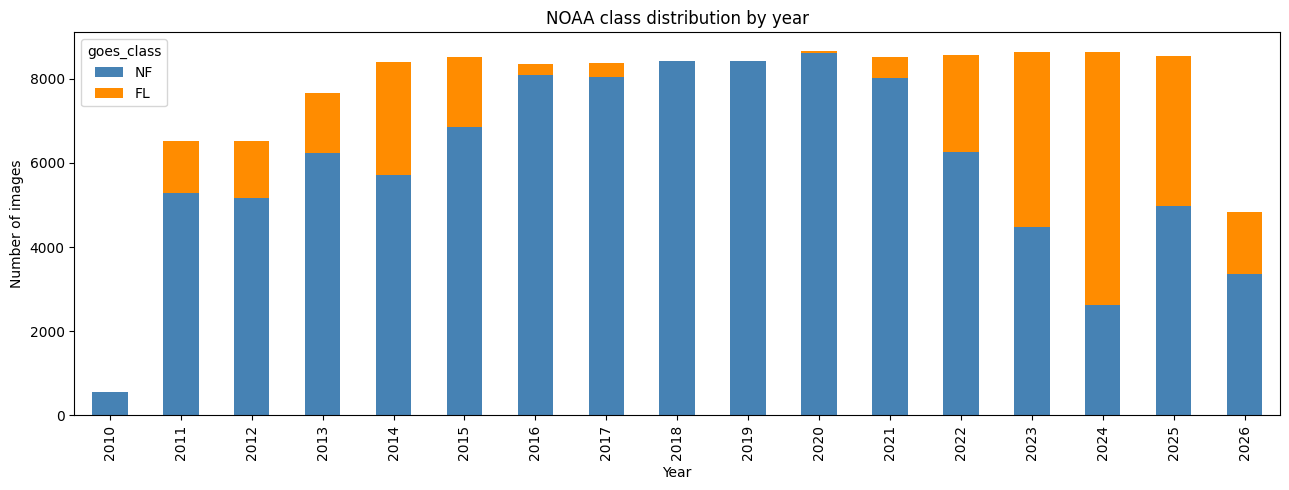

In [4]:
yearly[["NF", "FL"]].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 5),
    color=["steelblue", "darkorange"],
)

plt.title("NOAA class distribution by year")
plt.xlabel("Year")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

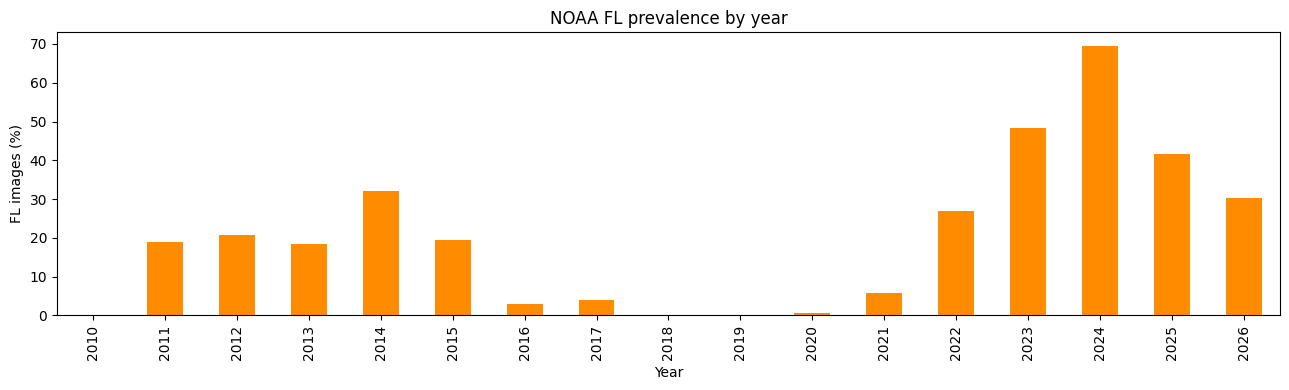

In [5]:
yearly["FL_percent"].plot(
    kind="bar",
    figsize=(13, 4),
    color="darkorange",
)

plt.title("NOAA FL prevalence by year")
plt.xlabel("Year")
plt.ylabel("FL images (%)")
plt.tight_layout()
plt.show()

In [6]:
# Overall NF and FL percentages
overall = labels["goes_class"].value_counts().sort_index()
overall_percent = overall / len(labels) * 100

print(f"NF: {overall[0]:,} ({overall_percent[0]:.2f}%)")
print(f"FL: {overall[1]:,} ({overall_percent[1]:.2f}%)")

NF: 101,118 (78.93%)
FL: 26,999 (21.07%)


In [7]:
yearly["NF_percent"] = 100 * yearly["NF"] / yearly["Total"]
yearly[["NF", "FL", "NF_percent", "FL_percent"]]

goes_class,NF,FL,NF_percent,FL_percent
year,,,,
2010,562,0,100.000000,0.000000
2011,5293,1235,81.081495,18.918505
2012,5158,1358,79.158993,20.841007
2013,6241,1415,81.517764,18.482236
2014,5703,2702,67.852469,32.147531
2015,6848,1663,80.460580,19.539420
2016,8087,250,97.001319,2.998681
2017,8047,330,96.060642,3.939358
2018,8417,0,100.000000,0.000000
